# 14 · The mobility of variable capital, and accumulation at historical cost

Two parameters of the cross-dual economy have so far been set by hand.

- **`μ_v`, the mobility of variable capital.** In the model, variable capital (the wage bill) moves towards the more profitable sectors, `dVᵢ/dt = σ_v·Sᵢ + μ_v·(rᵢ − r̄_V)·Vᵢ`. Notebook 6 and the paper found that this term drives the accumulation cycles: in random economies balanced growth loses stability at a Hopf bifurcation somewhere between `μ_v` ≈ 0.5 and 1.3, then gives way to limit cycles, quasi-periodic motion and chaos. Whether the cycles matter empirically depends on where the actual `μ_v` lies, and it had never been estimated.
- **How capital is valued.** The profit rate that moves capital has been computed on capital valued at current prices. The temporal single-system interpretation (TSSI) values capital advanced at what was actually paid for it, and until now the model offered that only as a valuation layer after the simulation (notebook 5). `tssi_dynamics = true` now makes the rate on capital advanced at historical cost, `Πᵢ/(Bᵢ + Vᵢ)`, drive accumulation, with the book value `B` of fixed capital in the state (`src/tssi.jl`).

This notebook estimates `μ_v` on the EU panel (`compute_labor_panel`, `estimate_variable_mobility`), places it against the Hopf point of Portugal's calibrated economy, and compares accumulation at current prices with accumulation at historical cost.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. Estimating `μ_v`

The 15 market sectors of 26 EU countries (`data/eurostat_eu_sectors.csv`). The model's equation in data terms:

`vg = σ_v·sv + μ_v·gap_V + country × sector + country-year`,

with `vg = 100·ΔV/Vₜ₋₁` the growth of the wage bill, `sv = 100·Sₜ₋₁/Vₜ₋₁` (last year's surplus, so that it is not tied to this year's wages through `S = GVA − V − CFC`) and `gap_V` the profit-rate gap to the mean of the country-year weighted by the wage bill, which sums to zero like the model's term. Country-year effects absorb common wage inflation and the business cycle. The wage bill also grows with sector-specific wage rates, which the model's `V` doesn't distinguish from hiring, so the same equation is estimated on employment growth `eg` too. Errors are clustered by country (and Driscoll–Kraay).

In [2]:
eu = CSV.read(joinpath("..", "..", "data", "eurostat_eu_sectors.csv"), DataFrame)
MARKET = setdiff(sort(String.(unique(eu.section))), NON_MARKET_SECTIONS)
LP = compute_labor_panel(eu; sections = MARKET)
LPi = compute_labor_panel(eu; sections = MARKET, self_employed = :imputed)
@printf("%d rows, %d countries; median wage-bill growth %.1f%%, employment growth %.1f%%\n",
        count(LP.valid_V), length(unique(LP.geo)), median(LP.vg[LP.valid_V]), median(LP.eg[LP.valid_V]))
cases = [("baseline", LP), ("self-employed imputed", LPi),
         ("without IE and LU", LP[.!in.(LP.geo, Ref(["IE", "LU"])), :]),
         ("up to 2008", LP[LP.year .<= 2008, :]), ("2009 on", LP[LP.year .>= 2009, :])]
est = DataFrame(case = String[], dependent = Symbol[], μ_v = Float64[], se = Float64[], se_DK = Float64[],
                σ_v = Float64[], se_σ = Float64[], n = Int[])
for (lab, P) in cases, dep in (:vg, :eg)
    e = estimate_variable_mobility(P; dependent = dep)
    push!(est, (lab, dep, e.μ_v, e.se_cluster, e.se_DK, e.λ_v, e.se_λ_v, e.n))
end
@printf("%-24s │ %28s │ %28s\n", "", "wage bill (vg): μ_v", "employment (eg): μ_v")
for lab in first.(cases)
    a = est[(est.case .== lab) .& (est.dependent .== :vg), :][1, :]
    b = est[(est.case .== lab) .& (est.dependent .== :eg), :][1, :]
    @printf("%-24s │ %6.3f (cl %.3f, DK %.3f) │ %6.3f (cl %.3f, DK %.3f)\n", lab, a.μ_v, a.se, a.se_DK, b.μ_v, b.se, b.se_DK)
end
println()
for lab in first.(cases)
    a = est[(est.case .== lab) .& (est.dependent .== :vg), :][1, :]
    @printf("%-24s σ_v (wage bill) = %.4f (se %.4f)\n", lab, a.σ_v, a.se_σ)
end

10665 rows, 26 countries; median wage-bill growth 4.9%, employment growth 1.0%
                         │          wage bill (vg): μ_v │         employment (eg): μ_v


baseline                 │  0.037 (cl 0.016, DK 0.014) │  0.024 (cl 0.009, DK 0.007)
self-employed imputed    │  0.074 (cl 0.018, DK 0.021) │  0.024 (cl 0.010, DK 0.009)


without IE and LU        │  0.028 (cl 0.014, DK 0.012) │  0.022 (cl 0.010, DK 0.007)
up to 2008               │  0.061 (cl 0.029, DK 0.013) │  0.030 (cl 0.013, DK 0.014)
2009 on                  │  0.027 (cl 0.032, DK 0.026) │  0.016 (cl 0.020, DK 0.010)

baseline                 σ_v (wage bill) = 0.0049 (se 0.0014)
self-employed imputed    σ_v (wage bill) = 0.0062 (se 0.0024)
without IE and LU        σ_v (wage bill) = 0.0056 (se 0.0015)
up to 2008               σ_v (wage bill) = 0.0115 (se 0.0050)
2009 on                  σ_v (wage bill) = 0.0086 (se 0.0020)


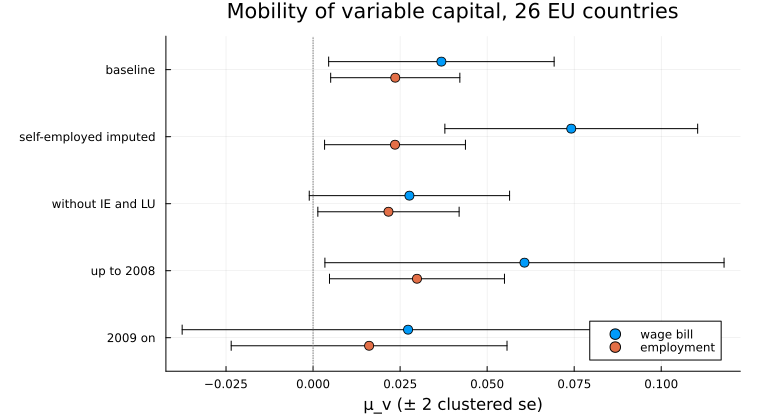

In [3]:
lab_order = reverse(first.(cases))
ys = 1:length(lab_order)
plt = plot(xlabel = "μ_v (± 2 clustered se)", yticks = (ys, lab_order), legend = :bottomright,
           title = "Mobility of variable capital, 26 EU countries", ylims = (0.5, length(ys) + 0.5))
for (dep, off, lab) in ((:vg, 0.12, "wage bill"), (:eg, -0.12, "employment"))
    d = [est[(est.case .== c) .& (est.dependent .== dep), :][1, :] for c in lab_order]
    scatter!(plt, [x.μ_v for x in d], ys .+ off; xerror = [2x.se for x in d], label = lab, ms = 5)
end
vline!(plt, [0]; color = :gray, ls = :dot, label = "")
plt

**Variable capital does follow profitability, but slowly.** On the wage bill `μ̂_v` = 0.037 (clustered se 0.016), and on employment 0.024 (se 0.009). The estimates are positive in every variant, 0.016–0.074, and at least two standard errors from zero in all but two: the wage-bill estimate without Ireland and Luxembourg is borderline (0.028, se 0.014), and from 2009 both are smaller and imprecise (0.027 and 0.016). Imputing the self-employed's labor income doubles the wage-bill estimate (0.074) but leaves the employment estimate unchanged (0.024), so the employment estimate is the more robust of the two.

The share of surplus spent on hiring, `σ_v`, is tiny in the data: 0.005–0.012, against the 0.1–0.15 the calibrations assume. Within a sector, wage bills barely respond to last year's surplus once the sector's trend and the country-year are absorbed. This is the counterpart, for variable capital, of what notebooks 11 and 13 found for constant capital: own surplus moves accumulation far less than the model's default shares imply.

## 2. Is the estimated `μ_v` in the cycle region?

Portugal's 15 market sectors in 2019, with notebook 13's departments and its estimates for constant capital (the linear reinvestment form, `η̂` = 0.15, `μ̂` = 0.06), in the cross-dual system. Balanced growth is continued in `μ_v` from 0 to 3 (`with_parameter(:μ_v)`, each point starting from the previous one), with the largest real part of the eigenvalues and the period of the dominant oscillation.

In [4]:
IP = compute_investment_panel(eu; sections = MARKET)
u = estimate_investment_function(IP; form = :linear).unrestricted
η̂, μ̂ = round(u.η, digits = 2), round(u.μ, digits = 2)
P19 = eu[(eu.geo .== "PT") .& (eu.year .== 2019), :]
σbar_pt = Dict(zip(IP.section[IP.geo .== "PT"], IP.σbar[IP.geo .== "PT"]))
depts = map(MARKET) do s
    row = P19[P19.section .== s, :][1, :]
    S = row.GVA - row.compensation - row.CFC
    Department(String(s); c = row.capital_stock, v = row.compensation, e = max(S / row.compensation, 0.1),
               σ_c = min(σbar_pt[s], 0.85), σ_v = 0.1, δ = row.CFC / row.capital_stock)
end
N = length(depts)
sol0, _, p = simulate_Ndept_custom(deepcopy(depts); T = 1.0, seed = 1, coupled = true, market_prices = true,
                                   reinvestment_form = :linear, η = η̂, μ = μ̂)
μv̂ = est[(est.case .== "baseline") .& (est.dependent .== :vg), :μ_v][1]
@printf("notebook 13's estimates: η = %.2f, μ = %.2f; estimated μ_v = %.3f\n", η̂, μ̂, μv̂)
μvs = [0.0:0.05:0.5; 0.6:0.1:3.0]
Xstart = Ref(sol0.u[1])   # natural continuation: each point starts from the previous one
sweep = map(enumerate(μvs)) do (k, m)
    q = with_parameter(p, :μ_v, m)
    eq = balanced_growth(q, Xstart[]; T_warmup = k == 1 ? 400.0 : 0.0)
    eq.converged || (eq = balanced_growth(q, sol0.u[1]))
    eq.converged && (Xstart[] = eq.X)
    dom = eq.eigenvalues[argmax(real.(eq.eigenvalues))]
    (μ_v = m, converged = eq.converged, max_re = real(dom), freq = abs(imag(dom)), g = eq.g,
     min_share = minimum(eq.X[1:2N]))
end |> DataFrame
for r in eachrow(sweep)
    (r.μ_v in (0.0, 0.05, 0.1, 0.2, 0.3, 0.5) || r.μ_v ≈ round(r.μ_v) || !r.converged) || continue
    @printf("μ_v = %4.2f │ converged %5s │ max Re λ %8.4f │ cycle period %6.1f years │ g %.2f%% │ min share %.5f\n",
            r.μ_v, r.converged, r.max_re, r.freq > 1e-8 ? 2π / r.freq : Inf, 100r.g, r.min_share)
end
k = findfirst(i -> sweep.converged[i] && sweep.max_re[i] >= 0, 1:nrow(sweep))
hopf = isnothing(k) ? nothing :
       sweep.μ_v[k-1] - sweep.max_re[k-1] * (sweep.μ_v[k] - sweep.μ_v[k-1]) / (sweep.max_re[k] - sweep.max_re[k-1])
println(isnothing(hopf) ? "no loss of stability up to μ_v = $(maximum(μvs))" :
        @sprintf("stability is lost at μ_v ≈ %.2f, %.0f times the estimate", hopf, hopf / μv̂))

notebook 13's estimates: η = 0.15, μ = 0.06; estimated μ_v = 0.037
μ_v = 0.00 │ converged  true │ max Re λ  -0.0458 │ cycle period   19.1 years │ g 7.24% │ min share 0.00177


μ_v = 0.05 │ converged  true │ max Re λ  -0.0456 │ cycle period   18.3 years │ g 7.26% │ min share 0.00173
μ_v = 0.10 │ converged  true │ max Re λ  -0.0449 │ cycle period   17.6 years │ g 7.27% │ min share 0.00169
μ_v = 0.20 │ converged  true │ max Re λ  -0.0426 │ cycle period   16.5 years │ g 7.28% │ min share 0.00164
μ_v = 0.30 │ converged  true │ max Re λ  -0.0396 │ cycle period   15.7 years │ g 7.29% │ min share 0.00159
μ_v = 0.50 │ converged  true │ max Re λ  -0.0323 │ cycle period   14.4 years │ g 7.29% │ min share 0.00152
μ_v = 1.00 │ converged  true │ max Re λ  -0.0104 │ cycle period   12.3 years │ g 7.28% │ min share 0.00142
μ_v = 2.00 │ converged  true │ max Re λ   0.0388 │ cycle period   10.2 years │ g 7.23% │ min share 0.00133
μ_v = 3.00 │ converged  true │ max Re λ   0.0891 │ cycle period    8.9 years │ g 7.19% │ min share 0.00128
stability is lost at μ_v ≈ 1.22, 33 times the estimate


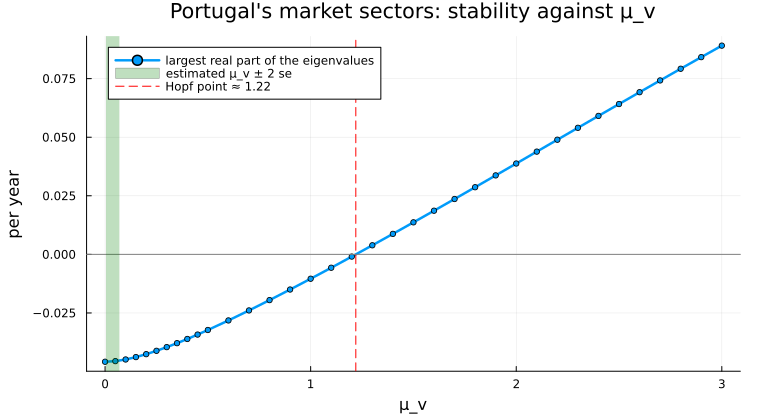

In [5]:
ok = sweep.converged
plt = plot(sweep.μ_v[ok], sweep.max_re[ok]; lw = 2.5, marker = :circle, ms = 3, label = "largest real part of the eigenvalues",
           xlabel = "μ_v", ylabel = "per year", title = "Portugal's market sectors: stability against μ_v")
hline!(plt, [0]; color = :gray, label = "")
b = est[(est.case .== "baseline") .& (est.dependent .== :vg), :][1, :]
vspan!(plt, [b.μ_v - 2b.se, b.μ_v + 2b.se]; alpha = 0.25, color = :green, label = "estimated μ_v ± 2 se")
isnothing(hopf) || vline!(plt, [hopf]; color = :red, ls = :dash, label = @sprintf("Hopf point ≈ %.2f", hopf))
plt

**Portugal's economy loses stability at `μ_v` ≈ 1.22**, inside the range found for random economies, through a pair of complex eigenvalues (a Hopf bifurcation) with a period of about 12 years. **The estimate is 33 times smaller.** Even the largest estimate plus two standard errors (0.074 + 2 × 0.018 = 0.11, self-employed imputed) is less than a tenth of the Hopf point. At the estimated `μ_v` the balanced growth path is as stable as with `μ_v` = 0 (largest real part −0.046), and the dominant mode is a damped oscillation with a period of 18–19 years.

So the accumulation cycles of notebook 6 and the paper are a property of the model at high mobility of variable capital, not of the economy the data describe: with the estimated `μ_v`, perturbations of the sectoral composition die out in damped waves.

## 3. Accumulation at historical cost

The same economy with `tssi_dynamics = true`. The book value `B` of each sector's fixed capital starts equal to `C` at the initial market prices; gross purchases are bought at the market price of the sector's capital good (the `A`-column-weighted price), depreciation removes `δB`, and the profit rate that drives reinvestment and mobility is `Πᵢ/(Bᵢ + Vᵢ)`. With market prices the lagged TSSI prices play no role (capital is bought at the prices of the day), so `τ` doesn't matter here; it only enters the variant without market prices, which has no interior balanced growth (notebooks 9–11).

In [6]:
"""Capital-weighted dispersion of the profit rates that drive accumulation."""
function dispersion(X, q)
    C, V = X[1:N], X[N+1:2N]
    B = _tssi_on(q) ? _book(X, q) : nothing
    ec = cross_dual_state(C, V, X[2N+1:3N], q; B = B)
    K = isnothing(B) ? C .+ V : B .+ V; r̄ = sum(ec.r .* K) / sum(K)
    sqrt(sum(K .* (ec.r .- r̄) .^ 2) / sum(K))
end
_, _, pt = simulate_Ndept_custom(deepcopy(depts); T = 1.0, seed = 1, coupled = true, market_prices = true,
                                 reinvestment_form = :linear, η = η̂, μ = μ̂, tssi_dynamics = true)
eqs = [("current prices", p, balanced_growth(p, sol0.u[1])),
       ("historical cost (TSSI)", pt, balanced_growth(pt, [sol0.u[1]; sol0.u[1][1:N]]))]
for (lab, q, eq) in eqs
    @printf("%-24s converged %s, stable %s: g %.2f%%, max Re λ %.4f, dispersion %.3f, min share %.4f\n", lab,
            eq.converged, eq.stable, 100eq.g, maximum(real.(eq.eigenvalues)), dispersion(eq.X, q), minimum(eq.X[1:2N]))
end
eqt = eqs[2][3]
bc = _book(eqt.X, pt) ./ eqt.X[1:N]
@printf("book value / C on the TSSI path: %.3f to %.3f (lowest %s, highest %s)\n", minimum(bc), maximum(bc),
        MARKET[argmin(bc)], MARKET[argmax(bc)])
r_cur = cross_dual_state(eqt.X[1:N], eqt.X[N+1:2N], eqt.X[2N+1:3N], pt).r
@printf("on that path, profit rates on book value vs current value differ by up to %.1f pp\n",
        100maximum(abs.(eqt.r .- r_cur)))

current prices           converged true, stable true: g 7.24%, max Re λ -0.0458, dispersion 0.072, min share 0.0018
historical cost (TSSI)   converged true, stable true: g 7.23%, max Re λ -0.0458, dispersion 0.077, min share 0.0018


book value / C on the TSSI path: 0.755 to 1.172 (lowest I, highest F)
on that path, profit rates on book value vs current value differ by up to 4.8 pp


current prices           year 200: dispersion 0.072, largest C share 0.21 (C)
historical cost (TSSI)   year 200: dispersion 0.077, largest C share 0.21 (C)


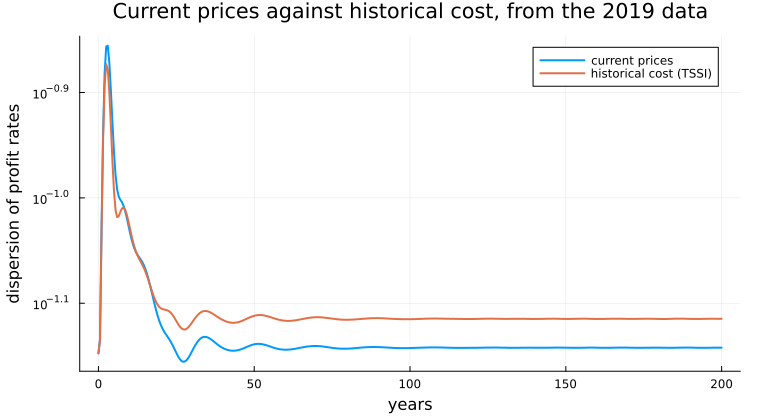

In [7]:
plt = plot(xlabel = "years", ylabel = "dispersion of profit rates", yscale = :log10,
           title = "Current prices against historical cost, from the 2019 data")
for (lab, tssi) in (("current prices", false), ("historical cost (TSSI)", true))
    s, _, q = simulate_Ndept_custom(deepcopy(depts); T = 200.0, seed = 1, coupled = true, market_prices = true,
                                    reinvestment_form = :linear, η = η̂, μ = μ̂, tssi_dynamics = tssi)
    d = [dispersion(X, q) for X in s.u]
    plot!(plt, s.t, d; lw = 2, label = lab)
    C = s.u[end][1:N]; k = argmax(C)
    @printf("%-24s year 200: dispersion %.3f, largest C share %.2f (%s)\n", lab, d[end], C[k] / sum(C), MARKET[k])
end
plt

**Valuing capital at historical cost barely changes the balanced growth path.** Growth is 7.23% against 7.24%, the largest real part of the eigenvalues is the same to four decimals (−0.0458), and every sector keeps a positive share. On the path the book value ranges from 0.76 times `C`, the capital stock the current-price rate divides by (accommodation and food, I), to 1.17 times (construction, F). Profit rates on book value differ from the rates on `C + V` by up to 4.8 pp, and their dispersion is a little wider (0.077 against 0.072).

Over 200 years from the 2019 data the two valuations follow the same course: both settle by year 100, with manufacturing (C) holding the largest share of constant capital (0.21) in both.

## 4. A price shock

As in notebook 13: starting from each balanced growth path, manufacturing's market price falls by 40% (−0.5 in logs). Its share of constant capital relative to the path, over 40 years.

current prices           lowest share 0.818 at year 2.2; profit rate right after -0.067; year 40: 1.000
historical cost (TSSI)   lowest share 0.820 at year 2.3; profit rate right after -0.062; year 40: 1.001


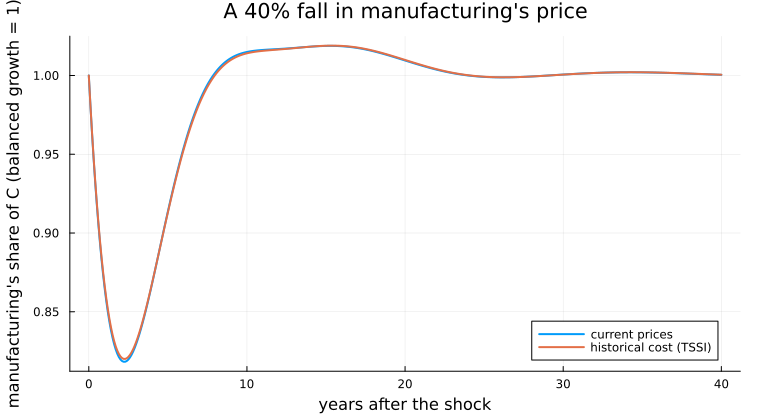

In [8]:
j = findfirst(==("C"), MARKET)
plt = plot(xlabel = "years after the shock", ylabel = "manufacturing's share of C (balanced growth = 1)",
           title = "A 40% fall in manufacturing's price")
for (lab, q, eq) in eqs
    X0 = copy(eq.X); X0[2N + j] -= 0.5
    s = solve(ODEProblem(cross_dual_system!, X0, (0.0, 40.0), q), Tsit5(), saveat = 0.1)
    share = [X[j] / sum(X[1:N]) for X in s.u] ./ (eq.X[j] / sum(eq.X[1:N]))
    rj = [(B = _tssi_on(q) ? _book(X, q) : nothing;
           cross_dual_state(X[1:N], X[N+1:2N], X[2N+1:3N], q; B = B).r[j]) for X in s.u]
    plot!(plt, s.t, share; lw = 2, label = lab)
    @printf("%-24s lowest share %.3f at year %.1f; profit rate right after %.3f; year 40: %.3f\n",
            lab, minimum(share), s.t[argmin(share)], rj[1], share[end])
end
plt

Under historical cost the fall is slightly milder: manufacturing's profit rate drops to −0.062 instead of −0.067, and its share of capital bottoms out at 0.820 of the path instead of 0.818. By year 40 both are back on the path. The difference is too small to see in the plot.

## What it means for the model

- **`μ_v` is estimated at 0.02–0.07** on the EU panel (0.037 on the wage bill, 0.024 on employment, se 0.009–0.018), positive and significant except after 2009. Variable capital follows profitability, an order of magnitude more slowly than the model's cycles need.
- **The accumulation cycles are outside the empirical range.** In Portugal's calibrated economy stability is lost at `μ_v` ≈ 1.22, 33 times the estimate. At the estimated `μ_v` balanced growth is stable, with damped oscillations of 18–19 years.
- **The share of surplus spent on hiring is tiny in the data** (`σ_v` ≈ 0.005–0.012 against the 0.1–0.15 assumed in the calibrations), as own surplus is a small part of what drives investment in constant capital (notebooks 11 and 13).
- **Valuing capital at historical cost changes little in this economy.** With `tssi_dynamics = true` the balanced growth path, its stability and the response to a price shock are almost the same as at current prices; book values stay between 0.76 and 1.17 times `C`. Where TSSI and simultaneist valuation are known to part is the level of the rate of profit when prices change persistently (notebook 5); this calibration, from one year's data, has no such trend. For how capital is allocated between sectors, the two valuations agree here.